# 07 · LLM baselines

Few-shot prompting and GPT-4o-mini fine-tuning through the OpenAI API, evaluated on stratified samples of the test set. The settings saved here (the few-shot model and a 400-posting sample) are from intermediate runs; the paper reports the final GPT-4o-mini runs on 1,000 test postings. The API key is a placeholder, and the fine-tuning cells are incomplete in the original (for example, the number of epochs is blank), so they do not run as is.

#**LLM Ceiling Baseline**

## few short

In [ ]:
import pandas as pd
import numpy as np
from openai import OpenAI
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import time

# Load data & Stratified Sampling
test_df = pd.read_csv('test_data_final.csv')

SAMPLE_SIZE = 400

sample_df = test_df.groupby('experience_level', group_keys=False).apply(
    lambda x: x.sample(n=min(len(x), int(SAMPLE_SIZE * len(x) / len(test_df))),
                       random_state=42)
).reset_index(drop=True)

print(f"Sampled {len(sample_df)} examples:")
print(sample_df['experience_level'].value_counts())

# OpenAI Client
client = OpenAI(api_key="OPEN_AI_KEY")

# Prompt
SYSTEM_PROMPT = """You are classifying job postings based on LinkedIn's experience level labels.

CRITICAL - LinkedIn's definitions:
1. Entry: LinkedIn "Entry level" or "Internship". Assistants, coordinators, technicians, analysts, specialists at entry level.
2. Mid: LinkedIn "Associate" level. Engineers, accountants, coordinators with 2-4 years experience.
3. Senior: LinkedIn "Mid-Senior level". Managers, consultants, leads, senior specialists, 5+ years. NOTE: Despite the name "Mid-Senior", this maps to Senior.
4. Executive: LinkedIn "Director" or "Executive". Directors, VPs, C-suite, Controllers, Chiefs.

Respond with ONLY one word: Entry, Mid, Senior, or Executive."""

FEW_SHOT_EXAMPLES = """
Example 1 (Entry):
Job Title: Shipping and Logistics Assistant
Description: We are seeking a dynamic Shipping and Logistics Assistant to join our growing team. The ideal candidate will be responsible for assisting with shipping operations.
Classification: Entry

Example 2 (Entry):
Job Title: MDR Analyst (Dayshift)
Description: Blackpoint Cyber is seeking an MDR Analyst. Founded by former National Security Agency (NSA) cyber operations experts, Blackpoint Cyber is in hyper-growth mode.
Classification: Entry

Example 3 (Entry):
Job Title: Critical Operations Technician I
Description: The Critical Operations Technician I is responsible for the installation, repair, and maintenance of IT, electrical, mechanical equipment. This role monitors operations and conducts routine assessment.
Classification: Entry

Example 4 (Mid):
Job Title: Building Engineer
Description: As a Building Engineer with Hines, you will embark on a career journey fueled by vision. Our legacy is rooted in innovation and excellence.
Classification: Mid

Example 5 (Mid):
Job Title: Accountant
Description: Responsible for real estate development and job costing accounting; perform professional-level accounting. Works closely with Project Managers and the finance team.
Classification: Mid

Example 6 (Mid):
Job Title: Technical Services Coordinator (NERC)
Description: Salary $70,000-$80,000. Responsible for generating station's NERC Reliability Standards compliance, execution, monitoring, and reporting activities.
Classification: Mid

Example 7 (Senior):
Job Title: Business Development Manager
Description: The Business Development Manager will manage and sell into an established book of business as well as develop new business in a defined geographical area.
Classification: Senior

Example 8 (Senior):
Job Title: Associate Project Manager
Description: Associate Project Manager will manage and ensure all phases are completed efficiently, within scope, on schedule, and within budget. Responsible for management of all project stages.
Classification: Senior

Example 9 (Senior):
Job Title: Chef De Partie - Full Time
Description: The Chef de Partie role is an ATL level leadership role in Prepared Foods focused on driving culinary excellence and hospitality experience on the Retail Floor.
Classification: Senior

Example 10 (Executive):
Job Title: Chief Operating Officer
Description: Seeking a dynamic and experienced Chief Operating Officer (COO) to join our team. This is an incredible opportunity to lead our operations and drive our company forward.
Classification: Executive

Example 11 (Executive):
Job Title: Controller
Description: Responsible for managing and directing the accounting and/or finance function. Establish and maintain a well-motivated team including training, supporting and developing each team member.
Classification: Executive

Example 12 (Executive):
Job Title: Director Program Management Office
Description: The Director, Program Management Office will play an integral role in managing client product portfolio and delivering projects. Salary Range: $190,000-$220,000.
Classification: Executive
"""

def classify_with_llm_o1(title, description):
    """o1 model classification"""

    full_prompt = f"""{SYSTEM_PROMPT}

{FEW_SHOT_EXAMPLES}

Now classify this job:
Job Title: {title}
Description: {description[:1500]}

IMPORTANT: Respond with ONLY a single word - one of: Entry, Mid, Senior, Executive
Classification:"""

    try:
        response = client.chat.completions.create(
            model="o1",
            messages=[
                {"role": "user", "content": full_prompt}
            ],
            max_completion_tokens=500
        )

        answer = response.choices[0].message.content.strip()

        for label in ['Entry', 'Mid', 'Senior', 'Executive']:
            if label.lower() in answer.lower():
                return label
        return 'Senior'

    except Exception as e:
        print(f"Error: {e}")
        time.sleep(5)
        return 'Senior'


# run prediction
print("\n" + "=" * 60)
print("Running LLM Classification (Few-shot)...")
print("=" * 60)

predictions = []
for idx, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    pred = classify_with_llm(row['title'], row['description'])
    predictions.append(pred)
    time.sleep(0.1)

sample_df['pred_llm'] = predictions

# evaluate
y_true = sample_df['experience_level']
y_pred = sample_df['pred_llm']

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average='macro')

print("\n" + "=" * 60)
print("LLM CEILING RESULTS (GPT-4o-mini, Few-shot)")
print("=" * 60)
print(f"Sample Size: {len(sample_df)}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Macro F1:  {macro_f1:.4f}")
print("\n" + "=" * 60)
print("Classification Report:")
print("=" * 60)
print(classification_report(y_true, y_pred, digits=4))

# Confusion Matrix
labels = ['Entry', 'Mid', 'Senior', 'Executive']
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('LLM Ceiling (GPT-4o-mini, Few-shot) - Confusion Matrix')
plt.tight_layout()
plt.savefig('llm_confusion_matrix.png', dpi=150)
plt.show()

# save result
sample_df.to_csv('llm_predictions.csv', index=False)
print("\nResults saved to llm_predictions.csv")

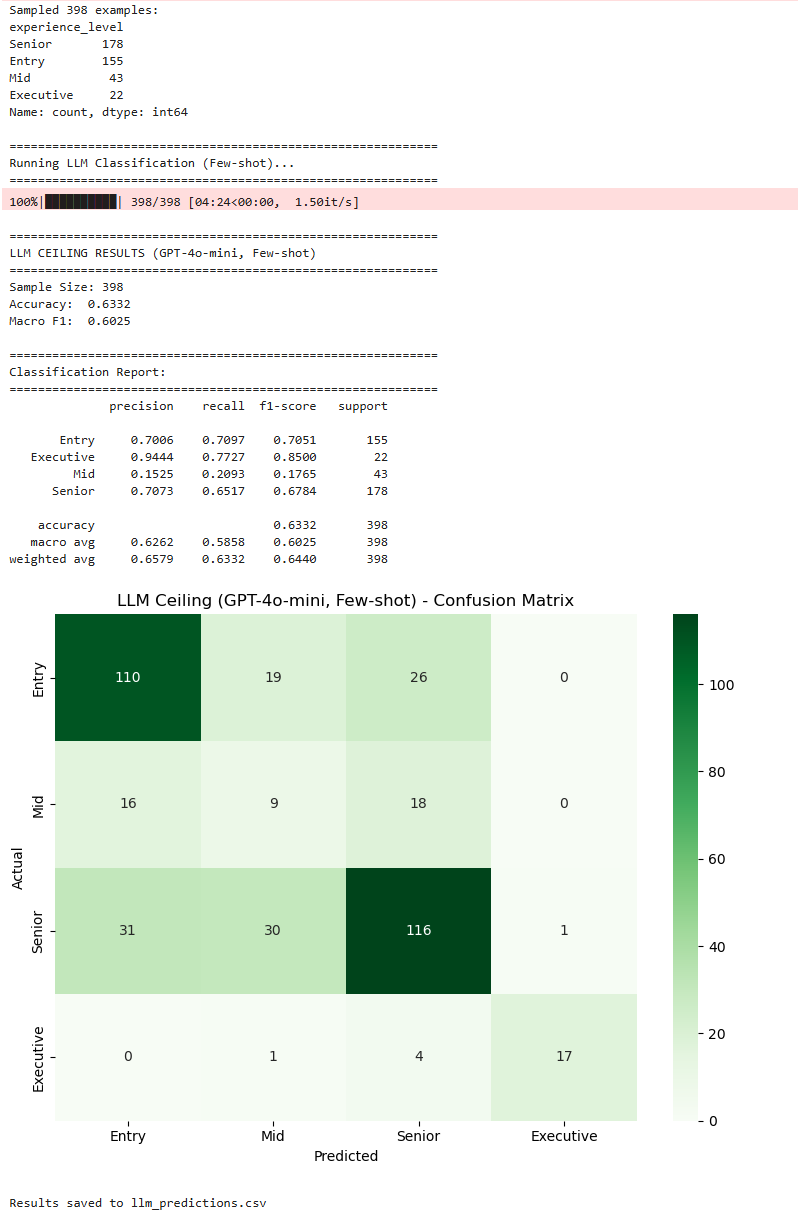

## fine-tuned

In [ ]:
# prepare Fine-tuning data
import json
import pandas as pd

# load data
train_df = pd.read_csv('train_data_final.csv')
dev_df = pd.read_csv('dev_data_final.csv')
test_df = pd.read_csv('test_data_final.csv')

def prepare_finetune_data(df, output_file, sample_size=1000):

    # Stratified sampling
    sample = df.groupby('experience_level', group_keys=False).apply(
        lambda x: x.sample(n=min(len(x), int(sample_size * len(x) / len(df))),
                           random_state=42)
    ).reset_index(drop=True)

    with open(output_file, 'w', encoding='utf-8') as f:
        for _, row in sample.iterrows():
            entry = {
                "messages": [
                    {
                        "role": "system",
                        "content": "Classify the job posting into exactly one category: Entry, Mid, Senior, or Executive. Respond with only the category name."
                    },
                    {
                        "role": "user",
                        "content": f"Job Title: {row['title']}\n\nJob Description: {row['description'][:1500]}"
                    },
                    {
                        "role": "assistant",
                        "content": row['experience_level']
                    }
                ]
            }
            f.write(json.dumps(entry) + '\n')

    print(f"Saved {len(sample)} examples to {output_file}")

    print(f"   Distribution: {sample['experience_level'].value_counts().to_dict()}")

# prepare data
prepare_finetune_data(train_df, 'train_finetune.jsonl', sample_size=1000)
prepare_finetune_data(dev_df, 'val_finetune.jsonl', sample_size=200)

In [ ]:
# upload data
from openai import OpenAI

client = OpenAI(api_key="OPEN_AI_KEY")

# upload training data
print("Uploading training file...")
train_file = client.files.create(
    file=open("train_finetune.jsonl", "rb"),
    purpose="fine-tune"
)
print(f"Train file ID: {train_file.id}")

# upload validation data
print("Uploading validation file...")
val_file = client.files.create(
    file=open("val_finetune.jsonl", "rb"),
    purpose="fine-tune"
)
print(f"Val file ID: {val_file.id}")

In [ ]:
# create Fine-tuning Job
job = client.fine_tuning.jobs.create(
    training_file=train_file.id,
    validation_file=val_file.id,
    model="gpt-4o-mini-2024-07-18",
    hyperparameters={
        "n_epochs":
    },
    suffix="job-classifier"
)

print(f"  Fine-tuning job created!")
print(f"   Job ID: {job.id}")
print(f"   Status: {job.status}")

In [ ]:
# track training status
job_id = job.id

status = client.fine_tuning.jobs.retrieve(job_id)

print(f"Status: {status.status}")
print(f"Created: {status.created_at}")

if status.status == "succeeded":
    print(f"\n Training complete!")
    print(f"Fine-tuned model: {status.fine_tuned_model}")
elif status.status == "failed":
    print(f"\n Training failed: {status.error}")
else:
    print(f"\n Still training... check again in a few minutes")

events = client.fine_tuning.jobs.list_events(fine_tuning_job_id=job_id, limit=10)
for event in events.data:
    print(f"  {event.message}")

In [ ]:
# use Fine-tuned model to predict
from tqdm import tqdm
from sklearn.metrics import accuracy_score, f1_score, classification_report

FINETUNED_MODEL = status.fine_tuned_model

def classify_with_finetuned(title, description):"
    try:
        response = client.chat.completions.create(
            model=FINETUNED_MODEL,
            messages=[
                {
                    "role": "system",
                    "content": "Classify the job posting into exactly one category: Entry, Mid, Senior, or Executive. Respond with only the category name."
                },
                {
                    "role": "user",
                    "content": f"Job Title: {title}\n\nJob Description: {description[:1500]}"
                }
            ],
            max_tokens=10,
            temperature=0
        )

        answer = response.choices[0].message.content.strip()

        for label in ['Entry', 'Mid', 'Senior', 'Executive']:
            if label.lower() in answer.lower():
                return label
        return 'Senior'  # default

    except Exception as e:
        print(f"Error: {e}")
        return 'Senior'

# validate on testing set
SAMPLE_SIZE = 400

sample_df = test_df.groupby('experience_level', group_keys=False).apply(
    lambda x: x.sample(n=min(len(x), int(SAMPLE_SIZE * len(x) / len(test_df))),
                       random_state=42)
).reset_index(drop=True)

print(f"Evaluating on {len(sample_df)} samples...")
print(sample_df['experience_level'].value_counts())

# run prediction
predictions = []
for idx, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    pred = classify_with_finetuned(row['title'], row['description'])
    predictions.append(pred)

sample_df['pred_finetuned'] = predictions

# evaluate result
y_true = sample_df['experience_level']
y_pred = sample_df['pred_finetuned']

print("\n" + "=" * 60)
print("FINE-TUNED MODEL RESULTS (GPT-4o-mini)")
print("=" * 60)
print(f"Sample Size: {len(sample_df)}")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro F1:  {f1_score(y_true, y_pred, average='macro'):.4f}")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, digits=4))

# save results
sample_df.to_csv('finetuned_predictions.csv', index=False)
print("\n Results saved to finetuned_predictions.csv")

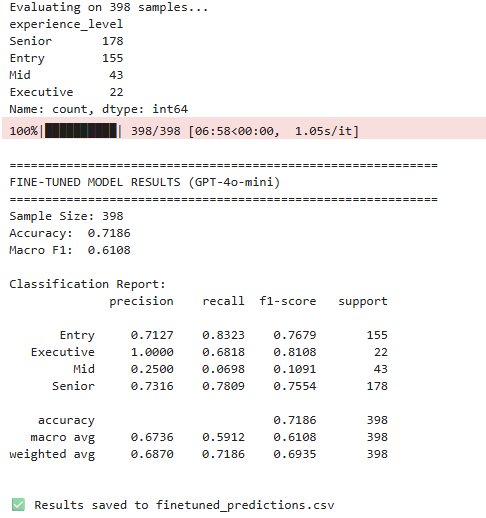